In [1]:
import os

In [2]:
BASE_DIR = "thesis_artifacts/preprocessing_run_01"
GRU_DIR = "thesis_artifacts/gru_run_01"
RF_DIR = "thesis_artifacts/rf_run_01"

In [3]:
os.listdir(BASE_DIR)
os.listdir(GRU_DIR)

['gru_predictions.npz', 'gru_test_predictions.csv', 'gru_val_predictions.csv']

In [4]:
%pip install numpy pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'd:\Pycode\Test\compile_pipeline\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [5]:
import numpy as np
import pandas as pd

In [6]:
import os

In [7]:
# =====================================================
# LOAD PREPROCESSED DATA + GRU OUTPUTS FROM GOOGLE DRIVE
# =====================================================


# ---- Load preprocessed tensors
data = np.load(os.path.join(BASE_DIR, "preprocessed_data_gru_run.npz"), allow_pickle=True)

X_tab_train = data["X_tab_train"]
X_tab_val   = data["X_tab_val"]
X_tab_test  = data["X_tab_test"]

y_train = data["y_train"]
y_val   = data["y_val"]
y_test  = data["y_test"]

label_mapping = data["label_mapping"].item()
num_classes   = int(data["num_classes"])

print("✅ Loaded preprocessed data")

# ---- Load GRU predictions
gru_out = np.load(os.path.join(GRU_DIR, "gru_predictions.npz"), allow_pickle=True)

gru_val_probs  = gru_out["val_probs"]
gru_test_probs = gru_out["test_probs"]

gru_val_preds  = gru_out["val_preds"]
gru_test_preds = gru_out["test_preds"]

class_names = gru_out["class_names"].tolist()

print("✅ Loaded GRU predictions")


✅ Loaded preprocessed data
✅ Loaded GRU predictions


In [8]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'd:\Pycode\Test\compile_pipeline\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [9]:
# # -----------------------------------------------------
# # GRU training history plots (loss/accuracy)
# # -----------------------------------------------------
# import matplotlib.pyplot as plt

# print("GRU artifact keys:", gru_out.files)

# # Helper to fetch the first available key from a list of candidates

# def pick_key(candidates):
#     for key in candidates:
#         if key in gru_out.files:
#             return key
#     return None

# loss_key = pick_key(["history_loss", "loss", "train_loss"])
# val_loss_key = pick_key(["history_val_loss", "val_loss", "validation_loss"])
# acc_key = pick_key(["history_accuracy", "accuracy", "acc", "train_accuracy"])
# val_acc_key = pick_key(["history_val_accuracy", "val_accuracy", "val_acc"])

# required = {
#     "train loss": loss_key,
#     "val loss": val_loss_key,
#     "train acc": acc_key,
#     "val acc": val_acc_key,
# }
# missing = [name for name, key in required.items() if key is None]
# if missing:
#     raise ValueError(
#         f"Missing history keys for: {missing}. "
#         f"Available keys: {list(gru_out.files)}"
#     )

# train_loss = gru_out[loss_key]
# val_loss = gru_out[val_loss_key]
# train_acc = gru_out[acc_key]
# val_acc = gru_out[val_acc_key]

# n_epochs = min(len(train_loss), len(val_loss), len(train_acc), len(val_acc))
# epochs = np.arange(1, n_epochs + 1)

# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# axes[0].plot(epochs, train_loss[:n_epochs], label="train")
# axes[0].plot(epochs, val_loss[:n_epochs], label="val")
# axes[0].set_title("GRU Loss")
# axes[0].set_xlabel("Epoch")
# axes[0].set_ylabel("Loss")
# axes[0].legend()
# axes[0].grid(True, alpha=0.3)

# axes[1].plot(epochs, train_acc[:n_epochs], label="train")
# axes[1].plot(epochs, val_acc[:n_epochs], label="val")
# axes[1].set_title("GRU Accuracy")
# axes[1].set_xlabel("Epoch")
# axes[1].set_ylabel("Accuracy")
# axes[1].legend()
# axes[1].grid(True, alpha=0.3)

# fig.suptitle("GRU Training History", y=1.05)
# plt.tight_layout()
# plt.show()


In [10]:
# =====================================================
# LOAD RANDOM FOREST ARTIFACTS (MODEL + PREDICTIONS)
# =====================================================

import joblib

rf_bundle = joblib.load(os.path.join(RF_DIR, "rf_model_bundle.joblib"))

rf_out = np.load(os.path.join(RF_DIR, "rf_predictions.npz"), allow_pickle=True)

rf_val_probs  = rf_out["val_probs"]
rf_test_probs = rf_out["test_probs"]

rf_val_preds  = rf_out["val_preds"]
rf_test_preds = rf_out["test_preds"]

if "class_names" in rf_out.files:
    rf_class_names = rf_out["class_names"].tolist()
elif "class_names" in globals():
    rf_class_names = class_names
else:
    rf_class_names = None

print("✅ Loaded RF model bundle + predictions")
print(f"rf_predictions keys: {rf_out.files}")


d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


✅ Loaded RF model bundle + predictions
rf_predictions keys: ['val_probs', 'test_probs', 'val_preds', 'test_preds', 'y_val', 'y_test', 'class_names']


In [11]:
# =====================================================
# STEP 5: Train KNN Model (STRATIFIED SUBSET)
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

print("\n" + "="*60)
print("🎯 TRAINING KNN MODEL (STRATIFIED SUBSET)")
print("="*60)

# -----------------------------------------------------
# 1) Define subset size (adjustable)
# -----------------------------------------------------
SUBSET_RATIO = 0.2   # 20% of training data (reasonable for KNN)
RANDOM_STATE = 42

sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=SUBSET_RATIO,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_train, y_train):
    X_knn_train = X_tab_train[subset_idx]
    y_knn_train = y_train.iloc[subset_idx] if hasattr(y_train, "iloc") else y_train[subset_idx]

print(f"✅ KNN trained on {len(X_knn_train):,} samples "
      f"({SUBSET_RATIO*100:.0f}% of training set)")

# -----------------------------------------------------
# 2) Train KNN
# -----------------------------------------------------
knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="minkowski",
    n_jobs=-1
)

print("🚀 Training KNN...")
knn.fit(X_knn_train, y_knn_train)




🎯 TRAINING KNN MODEL (STRATIFIED SUBSET)
✅ KNN trained on 1,523,841 samples (20% of training set)
🚀 Training KNN...


,n_neighbors,5
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,-1


In [12]:
# =====================================================
# STRATIFIED VALIDATION SUBSET FOR KNN
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# -----------------------------------------------------
# Config
# -----------------------------------------------------
VAL_SUBSET_SIZE = 200_000   # adjust: 100k–300k is reasonable
RANDOM_STATE = 42

print("\n" + "="*60)
print("📉 STRATIFIED VALIDATION SUBSET FOR KNN")
print("="*60)

# -----------------------------------------------------
# Create stratified subset
# -----------------------------------------------------
sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=VAL_SUBSET_SIZE,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_val, y_val):
    X_val_knn = X_tab_val[subset_idx]
    y_val_knn = y_val.iloc[subset_idx] if hasattr(y_val, "iloc") else y_val[subset_idx]

print(f"✅ Validation subset size: {X_val_knn.shape[0]}")
print("✅ Class distribution preserved")

# -----------------------------------------------------
# KNN Evaluation
# -----------------------------------------------------
print("\n" + "-"*60)
print("📊 KNN VALIDATION EVALUATION (STRATIFIED SUBSET)")
print("-"*60)

knn_val_preds = knn.predict(X_val_knn)

knn_val_acc = accuracy_score(y_val_knn, knn_val_preds)
print(f"✅ KNN Validation Accuracy: {knn_val_acc:.4f}")

print("\n📋 Classification Report:")
print(classification_report(
    y_val_knn,
    knn_val_preds,
    digits=4,
    zero_division=0
))



📉 STRATIFIED VALIDATION SUBSET FOR KNN
✅ Validation subset size: 200000
✅ Class distribution preserved

------------------------------------------------------------
📊 KNN VALIDATION EVALUATION (STRATIFIED SUBSET)
------------------------------------------------------------
✅ KNN Validation Accuracy: 0.9855

📋 Classification Report:
              precision    recall  f1-score   support

           0     0.9910    0.9925    0.9918     84027
           1     0.9960    0.9969    0.9964     72615
           2     0.9659    0.9709    0.9684     12626
           3     0.9754    0.9873    0.9813      8796
           4     0.9490    0.9768    0.9627      8195
           5     0.8941    0.8304    0.8611      2288
           6     0.9654    0.9504    0.9578      5965
           7     1.0000    0.9979    0.9990       478
           8     0.9975    0.9758    0.9866       414
           9     0.8525    0.2680    0.4078       388
          10     0.9391    0.9361    0.9376      3852
          11    

KNN Save

In [13]:
# =====================================================
# STRATIFIED VALIDATION SUBSET FOR KNN (FINAL)
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# -----------------------------------------------------
# Config (defensible size)
# -----------------------------------------------------
VAL_SUBSET_SIZE = 200_000   # 100k–300k is academically safe
RANDOM_STATE = 42

print("\n" + "="*60)
print("📉 STRATIFIED VALIDATION SUBSET FOR KNN")
print("="*60)

# -----------------------------------------------------
# Create stratified subset from validation set
# -----------------------------------------------------
sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=VAL_SUBSET_SIZE,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_val, y_val):
    X_val_knn = X_tab_val[subset_idx]
    y_val_knn = y_val.iloc[subset_idx] if hasattr(y_val, "iloc") else y_val[subset_idx]

print(f"✅ Validation subset size : {X_val_knn.shape[0]:,}")
print("✅ Class distribution preserved")

# -----------------------------------------------------
# KNN Evaluation
# -----------------------------------------------------
print("\n" + "-"*60)
print("📊 KNN VALIDATION EVALUATION (STRATIFIED)")
print("-"*60)

knn_val_preds = knn.predict(X_val_knn)

knn_val_acc = accuracy_score(y_val_knn, knn_val_preds)
print(f"✅ KNN Validation Accuracy: {knn_val_acc:.4f}")

print("\n📋 Classification Report:")
print(classification_report(
    y_val_knn,
    knn_val_preds,
    digits=4,
    zero_division=0
))



📉 STRATIFIED VALIDATION SUBSET FOR KNN
✅ Validation subset size : 200,000
✅ Class distribution preserved

------------------------------------------------------------
📊 KNN VALIDATION EVALUATION (STRATIFIED)
------------------------------------------------------------
✅ KNN Validation Accuracy: 0.9855

📋 Classification Report:
              precision    recall  f1-score   support

           0     0.9910    0.9925    0.9918     84027
           1     0.9960    0.9969    0.9964     72615
           2     0.9659    0.9709    0.9684     12626
           3     0.9754    0.9873    0.9813      8796
           4     0.9490    0.9768    0.9627      8195
           5     0.8941    0.8304    0.8611      2288
           6     0.9654    0.9504    0.9578      5965
           7     1.0000    0.9979    0.9990       478
           8     0.9975    0.9758    0.9866       414
           9     0.8525    0.2680    0.4078       388
          10     0.9391    0.9361    0.9376      3852
          11     0.69

In [15]:
# =====================================================
# STRATIFIED VALIDATION SUBSET FOR KNN (FINAL)
# =====================================================
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# -----------------------------------------------------
# Config (defensible size)
# -----------------------------------------------------
VAL_SUBSET_SIZE = 200_000   # 100k–300k is academically safe
RANDOM_STATE = 42

print("\n" + "="*60)
print("📉 STRATIFIED VALIDATION SUBSET FOR KNN")
print("="*60)

# -----------------------------------------------------
# Create stratified subset from validation set
# -----------------------------------------------------
sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=VAL_SUBSET_SIZE,
    random_state=RANDOM_STATE
)

for subset_idx, _ in sss.split(X_tab_val, y_val):
    X_val_knn = X_tab_val[subset_idx]
    y_val_knn = y_val.iloc[subset_idx] if hasattr(y_val, "iloc") else y_val[subset_idx]

print(f"✅ Validation subset size : {X_val_knn.shape[0]:,}")
print("✅ Class distribution preserved")

# -----------------------------------------------------
# KNN Evaluation
# -----------------------------------------------------
print("\n" + "-"*60)
print("📊 KNN VALIDATION EVALUATION (STRATIFIED)")
print("-"*60)

knn_val_preds = knn.predict(X_val_knn)

knn_val_acc = accuracy_score(y_val_knn, knn_val_preds)
print(f"✅ KNN Validation Accuracy: {knn_val_acc:.4f}")

print("\n📋 Classification Report:")
print(classification_report(
    y_val_knn,
    knn_val_preds,
    digits=4,
    zero_division=0
))



📉 STRATIFIED VALIDATION SUBSET FOR KNN
✅ Validation subset size : 200,000
✅ Class distribution preserved

------------------------------------------------------------
📊 KNN VALIDATION EVALUATION (STRATIFIED)
------------------------------------------------------------
✅ KNN Validation Accuracy: 0.9855

📋 Classification Report:
              precision    recall  f1-score   support

           0     0.9910    0.9925    0.9918     84027
           1     0.9960    0.9969    0.9964     72615
           2     0.9659    0.9709    0.9684     12626
           3     0.9754    0.9873    0.9813      8796
           4     0.9490    0.9768    0.9627      8195
           5     0.8941    0.8304    0.8611      2288
           6     0.9654    0.9504    0.9578      5965
           7     1.0000    0.9979    0.9990       478
           8     0.9975    0.9758    0.9866       414
           9     0.8525    0.2680    0.4078       388
          10     0.9391    0.9361    0.9376      3852
          11     0.69

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Basic aggregated metrics helper

def build_eval_row(model_name, split, y_true, preds, probs=None):
    acc = accuracy_score(y_true, preds)
    prec, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        preds,
        average="macro",
        zero_division=0,
    )
    return {
        "model": model_name,
        "split": split,
        "accuracy": acc,
        "macro_precision": prec,
        "macro_recall": recall,
        "macro_f1": f1,
    }


In [ ]:
# -----------------------------------------------------
# Ensure full-size KNN predictions exist before evaluation
# -----------------------------------------------------
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

eval_rows = []

# Individual models (full validation/test splits)
eval_rows.append(build_eval_row("GRU", "val", y_val, gru_val_preds))
eval_rows.append(build_eval_row("GRU", "test", y_test, gru_test_preds))

eval_rows.append(build_eval_row("RF", "val", y_val, rf_val_preds))
eval_rows.append(build_eval_row("RF", "test", y_test, rf_test_preds))

eval_rows.append(build_eval_row("KNN", "val", y_val, knn_val_preds))
eval_rows.append(build_eval_row("KNN", "test", y_test, knn_test_preds))

eval_df = pd.DataFrame(eval_rows)

display(
    eval_df
    .sort_values(["split", "model"])
    .set_index(["split", "model"])
)

In [18]:
eval_df = pd.DataFrame(eval_rows)

display(
    eval_df
    .sort_values(["split", "model"])
    .set_index(["split", "model"])
)


accuracy  macro_precision  macro_recall  macro_f1
split          model                                                   
test           GRU    0.986206         0.828837      0.732115  0.751737
val            GRU    0.986136         0.812400      0.713492  0.734447
               RF     0.917303         0.773704      0.928479  0.799075
val_stratified KNN    0.985500         0.850248      0.747796  0.780157

In [20]:
import pandas as pd
from sklearn.metrics import classification_report

def per_class_metrics(y_true, y_pred, class_names, model_name, split):
    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    
    df = (
        pd.DataFrame(report)
        .transpose()
        .iloc[:-3]   # buang accuracy / macro / weighted
        .reset_index()
        .rename(columns={"index": "class"})
    )
    
    df["model"] = model_name
    df["split"] = split
    
    return df[[
        "model", "split", "class",
        "precision", "recall", "f1-score", "support"
    ]]


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

def fpr_fnr_per_class(y_true, y_pred, class_names, model_name, split):
    cm = confusion_matrix(y_true, y_pred)
    results = []
    
    for i, cls in enumerate(class_names):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = cm.sum() - (TP + FP + FN)
        
        FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
        FNR = FN / (FN + TP) if (FN + TP) > 0 else 0
        
        results.append({
            "model": model_name,
            "split": split,
            "class": cls,
            "FPR": FPR,
            "FNR": FNR
        })
    
    return pd.DataFrame(results)


In [29]:
from sklearn.model_selection import StratifiedShuffleSplit

# -----------------------------------------------------
# Build stratified eval set (shared by ALL models)
# -----------------------------------------------------
EVAL_SIZE = 200_000
RANDOM_STATE = 42

sss = StratifiedShuffleSplit(
    n_splits=1,
    test_size=EVAL_SIZE,
    random_state=RANDOM_STATE
)

for _, eval_idx in sss.split(X_tab_val, y_val):
    X_eval = X_tab_val[eval_idx]
    y_eval = y_val.iloc[eval_idx] if hasattr(y_val, "iloc") else y_val[eval_idx]

print(f"✅ Shared evaluation set size: {X_eval.shape[0]}")


✅ Shared evaluation set size: 200000


In [ ]:
# =====================================================
# Full validation/test KNN probabilities & predictions (for ensembles/report)
# =====================================================
print("📤 Computing KNN probabilities on full validation/test sets...")

knn_val_probs = knn.predict_proba(X_tab_val)
knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

print(f"✅ KNN full-set probs ready")
print(f"   val shape: {knn_val_probs.shape} (y_val: {len(y_val)})")
print(f"   test shape: {knn_test_probs.shape} (y_test: {len(y_test)})")

,model,class,precision,recall,f1-score,support,accuracy_overall
0,GRU,benign,0.992331,0.994775,0.993552,84027.0,0.985965
1,GRU,ddos,0.996689,0.995029,0.995858,72615.0,0.985965
2,GRU,scanning,0.977804,0.976952,0.977378,12626.0,0.985965
3,GRU,reconnaissance,0.973411,0.982265,0.977818,8796.0,0.985965
4,GRU,xss,0.952662,0.984747,0.968439,8195.0,0.985965
...,...,...,...,...,...,...,...
75,Ensemble (equal),generic,0.816327,0.727273,0.769231,55.0,0.989300
76,Ensemble (equal),analysis,0.125000,0.250000,0.166667,8.0,0.989300
77,Ensemble (equal),shellcode,0.307692,0.461538,0.369231,26.0,0.989300
78,Ensemble (equal),mitm,1.000000,0.909091,0.952381,11.0,0.989300



✅ Per-class precision/recall/F1 and overall accuracy computed for shared eval set.


In [ ]:
# -----------------------------------------------------
# Soft voting ensemble (GRU + RF + KNN)
# -----------------------------------------------------
# Ensure full-size KNN probs/preds exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)
knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Average class probabilities
ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0

ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

# Evaluation for ensemble
ensemble_rows = []
ensemble_rows.append(build_eval_row("Ensemble", "val", y_val, ensemble_val_preds))
ensemble_rows.append(build_eval_row("Ensemble", "test", y_test, ensemble_test_preds))

display(pd.DataFrame(ensemble_rows).set_index(["split", "model"]))

NameError: name 'knn_val_probs' is not defined

In [ ]:
# -----------------------------------------------------
# Overall FPR/FNR per model (val/test)
# -----------------------------------------------------
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

label_list = sorted(np.unique(np.concatenate([np.asarray(y_train), np.asarray(y_val), np.asarray(y_test)])))

# Ensure full-size KNN probs/preds exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)
knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble predictions exist
if 'ensemble_val_preds' not in globals() or len(ensemble_val_preds) != len(y_val):
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

model_preds_overall = {
    "GRU": {"val": gru_val_preds, "test": gru_test_preds},
    "RF": {"val": rf_val_preds, "test": rf_test_preds},
    "KNN": {"val": knn_val_preds, "test": knn_test_preds},
    "Ensemble (equal)": {"val": ensemble_val_preds, "test": ensemble_test_preds},
}

# Include best-weight ensemble if present
if "best" in globals() and isinstance(best, dict) and best.get("weights") is not None:
    w_gru, w_rf, w_knn = best["weights"]
    ens_val_probs_w = w_gru * gru_val_probs + w_rf * rf_val_probs + w_knn * knn_val_probs
    ens_test_probs_w = w_gru * gru_test_probs + w_rf * rf_test_probs + w_knn * knn_test_probs
    ens_val_preds_w = np.argmax(ens_val_probs_w, axis=1)
    ens_test_preds_w = np.argmax(ens_test_probs_w, axis=1)
    model_preds_overall[f"Ensemble w=({w_gru:.1f},{w_rf:.1f},{w_knn:.1f})"] = {
        "val": ens_val_preds_w,
        "test": ens_test_preds_w,
    }

overall_rows = []
for model_name, splits in model_preds_overall.items():
    for split_name, preds in splits.items():
        y_true = y_val if split_name == "val" else y_test
        cm = confusion_matrix(y_true, preds, labels=label_list)
        fp = cm.sum(axis=0) - np.diag(cm)
        fn = cm.sum(axis=1) - np.diag(cm)
        tn = cm.sum() - (np.diag(cm) + fp + fn)
        fpr = fp.sum() / (fp.sum() + tn.sum() + 1e-9)
        fnr = fn.sum() / (fn.sum() + np.diag(cm).sum() + 1e-9)
        overall_rows.append({
            "model": model_name,
            "split": split_name,
            "fpr_overall": fpr,
            "fnr_overall": fnr,
        })

overall_fpr_fnr_df = pd.DataFrame(overall_rows)
display(overall_fpr_fnr_df.sort_values(["split", "model"]).set_index(["split", "model"]))

In [ ]:
# -----------------------------------------------------
# Grid search soft-voting ensemble weights (GRU, RF, KNN)
# -----------------------------------------------------
import itertools

# Ensure full-size KNN probs exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

# Candidate weights (light grid to keep runtime low)
weight_options = [0.2, 0.3, 0.4, 0.5]
weight_grid = [ws for ws in itertools.product(weight_options, repeat=3) if abs(sum(ws) - 1.0) < 1e-6]

best = {"weights": None, "macro_f1": -1, "val_row": None}

for w_gru, w_rf, w_knn in weight_grid:
    val_probs = w_gru * gru_val_probs + w_rf * rf_val_probs + w_knn * knn_val_probs
    val_preds = np.argmax(val_probs, axis=1)
    row = build_eval_row(
        model_name=f"Ensemble w=({w_gru:.1f},{w_rf:.1f},{w_knn:.1f})",
        split="val",
        y_true=y_val,
        preds=val_preds,
        probs=val_probs,
    )
    if row["macro_f1"] > best["macro_f1"]:
        best = {"weights": (w_gru, w_rf, w_knn), "macro_f1": row["macro_f1"], "val_row": row}

# Re-evaluate on val/test with best weights
w_gru, w_rf, w_knn = best["weights"]
best_val_probs = w_gru * gru_val_probs + w_rf * rf_val_probs + w_knn * knn_val_probs
best_test_probs = w_gru * gru_test_probs + w_rf * rf_test_probs + w_knn * knn_test_probs

best_val_preds = np.argmax(best_val_probs, axis=1)
best_test_preds = np.argmax(best_test_probs, axis=1)

ensemble_grid_rows = []
ensemble_grid_rows.append(best["val_row"])
ensemble_grid_rows.append(
    build_eval_row(
        model_name=f"Ensemble w=({w_gru:.1f},{w_rf:.1f},{w_knn:.1f})",
        split="test",
        y_true=y_test,
        preds=best_test_preds,
        probs=best_test_probs,
    )
)

display(pd.DataFrame(ensemble_grid_rows).set_index(["split", "model"]))
print(f"Best weights (GRU, RF, KNN): {best['weights']}, macro_f1_val={best['macro_f1']:.4f}")

In [ ]:
# =====================================================
# GRID SEARCH FOR ENSEMBLE WEIGHT OPTIMIZATION (GRU, RF, KNN)
# =====================================================
import numpy as np
import pandas as pd
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix

print("="*60)
print("🔍 GRID SEARCH FOR OPTIMAL ENSEMBLE WEIGHTS")
print("="*60)

# -----------------------------------------------------
# Ensure full-size KNN probabilities are available
# -----------------------------------------------------
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    print("📤 Computing KNN validation probabilities...")
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    print("📤 Computing KNN test probabilities...")
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# -----------------------------------------------------
# Weight grid (must sum to 1.0)
# -----------------------------------------------------
weight_options = np.arange(0.2, 1.0, 0.05)
print(f"Weight options: {weight_options}")

valid_combinations = []
for w_gru in weight_options:
    for w_knn in weight_options:
        w_rf = 1.0 - w_gru - w_knn
        if 0.0 <= w_rf <= 1.0:
            w_tuple = (round(w_gru, 2), round(w_knn, 2), round(w_rf, 2))
            if abs(sum(w_tuple) - 1.0) < 0.01:
                valid_combinations.append(w_tuple)

print(f"✅ Generated {len(valid_combinations)} valid combinations")

# -----------------------------------------------------
# Evaluation function (balanced FP/FN trade-off)
# -----------------------------------------------------

def evaluate_ensemble(w_gru, w_knn, w_rf, probs_gru, probs_knn, probs_rf, y_true):
    ensemble_probs = w_gru * probs_gru + w_knn * probs_knn + w_rf * probs_rf
    y_pred = np.argmax(ensemble_probs, axis=1)

    accuracy = accuracy_score(y_true, y_pred)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted")
    macro_f1 = f1_score(y_true, y_pred, average="macro")

    cm = confusion_matrix(y_true, y_pred)

    # FP: normal (class 0) predicted as attack
    if cm.shape[0] > 0:
        fp_count = cm[0, 1:].sum() if cm.shape[1] > 1 else 0
        fp_rate = fp_count / (cm[0, :].sum() + 1e-10)
    else:
        fp_rate = 0.0

    # FN: attack predicted as normal
    if cm.shape[0] > 1:
        fn_count = cm[1:, 0].sum()
        fn_rate = fn_count / (cm[1:, :].sum() + 1e-10)
    else:
        fn_rate = 0.0

    attack_mask = np.asarray(y_true) != 0
    if np.any(attack_mask):
        attack_recall = recall_score(np.asarray(y_true)[attack_mask], y_pred[attack_mask], average="macro", zero_division=0)
        attack_precision = precision_score(np.asarray(y_true)[attack_mask], y_pred[attack_mask], average="macro", zero_division=0)
        attack_f1 = f1_score(np.asarray(y_true)[attack_mask], y_pred[attack_mask], average="macro", zero_division=0)
    else:
        attack_recall = attack_precision = attack_f1 = 0.0

    per_class_prec = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_rec = recall_score(y_true, y_pred, average=None, zero_division=0)
    normal_precision = per_class_prec[0] if len(per_class_prec) > 0 else 0.0
    normal_recall = per_class_rec[0] if len(per_class_rec) > 0 else 0.0

    fp_fn_balance = 1.0 - (fp_rate + fn_rate) / 2.0

    combined_score = (
        0.25 * macro_f1 +
        0.25 * attack_f1 +
        0.20 * fp_fn_balance +
        0.15 * attack_recall +
        0.15 * normal_precision
    )

    return {
        "accuracy": accuracy,
        "weighted_f1": weighted_f1,
        "macro_f1": macro_f1,
        "attack_recall": attack_recall,
        "attack_precision": attack_precision,
        "attack_f1": attack_f1,
        "normal_precision": normal_precision,
        "normal_recall": normal_recall,
        "fp_rate": fp_rate,
        "fn_rate": fn_rate,
        "fp_fn_balance": fp_fn_balance,
        "combined_score": combined_score,
    }

# -----------------------------------------------------
# Grid search on validation set
# -----------------------------------------------------
print("\n🚀 Starting grid search on validation set...")
results = []
for i, (w_gru, w_knn, w_rf) in enumerate(valid_combinations):
    if (i + 1) % 20 == 0:
        print(f"Progress: {i+1}/{len(valid_combinations)}")
    metrics = evaluate_ensemble(w_gru, w_knn, w_rf, gru_val_probs, knn_val_probs, rf_val_probs, y_val)
    results.append({"w_gru": w_gru, "w_knn": w_knn, "w_rf": w_rf, **metrics})

results_df = pd.DataFrame(results)
print(f"✅ Grid search complete ({len(results_df)} combos)")

best_idx = results_df["combined_score"].idxmax()
best_row = results_df.loc[best_idx]

print("\n🎯 Best weights (val):")
print(f"   GRU: {best_row.w_gru:.2f}  KNN: {best_row.w_knn:.2f}  RF: {best_row.w_rf:.2f}")
print(f"   Combined: {best_row.combined_score:.4f}  Macro F1: {best_row.macro_f1:.4f}")
print(f"   FP rate: {best_row.fp_rate:.4f}  FN rate: {best_row.fn_rate:.4f}")

print("\n📊 Top 10 configs (val, by combined_score):")
display(results_df.sort_values("combined_score", ascending=False).head(10)[[
    "w_gru", "w_knn", "w_rf", "combined_score", "macro_f1", "attack_recall", "normal_precision", "fp_rate", "fn_rate"
]])

# -----------------------------------------------------
# Baseline vs best (validation)
# -----------------------------------------------------
baseline_metrics = evaluate_ensemble(1/3, 1/3, 1/3, gru_val_probs, knn_val_probs, rf_val_probs, y_val)
print("\n🔹 Baseline (1/3 each):")
print(f"   Acc: {baseline_metrics['accuracy']:.4f}  Weighted F1: {baseline_metrics['weighted_f1']:.4f}  Attack Recall: {baseline_metrics['attack_recall']:.4f}")

print("🔹 Best (val-optimal):")
print(f"   Acc: {best_row.accuracy:.4f}  Weighted F1: {best_row.weighted_f1:.4f}  Attack Recall: {best_row.attack_recall:.4f}")

# -----------------------------------------------------
# Test set evaluation for best weights
# -----------------------------------------------------
print("\n" + "="*60)
print("📈 TEST SET EVALUATION (best weights from val)")
print("="*60)

best_test = evaluate_ensemble(best_row.w_gru, best_row.w_knn, best_row.w_rf, gru_test_probs, knn_test_probs, rf_test_probs, y_test)

gru_test_preds = np.argmax(gru_test_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)
rf_test_preds = rf_bundle.get("model", None).predict(X_tab_test) if isinstance(rf_bundle, dict) and "model" in rf_bundle else np.argmax(rf_test_probs, axis=1)

print("Individual model accuracies (test):")
print(f"   GRU: {accuracy_score(y_test, gru_test_preds):.4f}")
print(f"   KNN: {accuracy_score(y_test, knn_test_preds):.4f}")
print(f"   RF : {accuracy_score(y_test, rf_test_preds):.4f}")

print("\nEnsemble (1/3 each) test:")
baseline_test = evaluate_ensemble(1/3, 1/3, 1/3, gru_test_probs, knn_test_probs, rf_test_probs, y_test)
print(f"   Acc: {baseline_test['accuracy']:.4f}  Weighted F1: {baseline_test['weighted_f1']:.4f}  Attack Recall: {baseline_test['attack_recall']:.4f}")

print("\nEnsemble (best weights) test:")
print(f"   Weights -> GRU: {best_row.w_gru:.2f}, KNN: {best_row.w_knn:.2f}, RF: {best_row.w_rf:.2f}")
print(f"   Acc: {best_test['accuracy']:.4f}  Weighted F1: {best_test['weighted_f1']:.4f}  Attack Recall: {best_test['attack_recall']:.4f}  Combined: {best_test['combined_score']:.4f}")

improvement = best_test['accuracy'] - baseline_test['accuracy']
print(f"\n✨ Test accuracy improvement vs baseline: {improvement:.4f} ({improvement*100:.2f}%)")

🔍 GRID SEARCH FOR OPTIMAL ENSEMBLE WEIGHTS
Weight options: [0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75 0.8  0.85
 0.9  0.95]
✅ Generated 91 valid combinations

🚀 Starting grid search on validation set...
Progress: 20/91
Progress: 40/91
Progress: 60/91
Progress: 80/91
✅ Grid search complete (91 combos)

🎯 Best weights (val):
   GRU: 0.20  KNN: 0.20  RF: 0.60
   Combined: 0.8805  Macro F1: 0.8318
   FP rate: 0.0081  FN rate: 0.0028

📊 Top 10 configs (val, by combined_score):


,w_gru,w_knn,w_rf,combined_score,macro_f1,attack_recall,normal_precision,fp_rate,fn_rate
0,0.20,0.20,0.60,0.880472,0.831776,0.831606,0.996119,0.008124,0.002800
13,0.25,0.20,0.55,0.878882,0.834054,0.823360,0.995843,0.005710,0.003007
1,0.20,0.25,0.55,0.878321,0.833036,0.821777,0.995814,0.005963,0.003028
14,0.25,0.25,0.50,0.876399,0.832280,0.814574,0.995585,0.005347,0.003196
25,0.30,0.20,0.50,0.876167,0.831841,0.814942,0.995581,0.005307,0.003199
2,0.20,0.30,0.50,0.876059,0.832093,0.812512,0.995524,0.005480,0.003240
36,0.35,0.20,0.45,0.872939,0.829131,0.803384,0.995287,0.005218,0.003413
26,0.30,0.25,0.45,0.872046,0.828840,0.798201,0.995268,0.005163,0.003427
15,0.25,0.30,0.45,0.871283,0.828610,0.793877,0.995249,0.005141,0.003441
3,0.20,0.35,0.45,0.870151,0.827436,0.789523,0.995202,0.005277,0.003475



🔹 Baseline (1/3 each):
   Acc: 0.9893  Weighted F1: 0.9890  Attack Recall: 0.7603
🔹 Best (val-optimal):
   Acc: 0.9882  Weighted F1: 0.9884  Attack Recall: 0.8316

📈 TEST SET EVALUATION (best weights from val)


[Parallel(n_jobs=6)]: Using backend ThreadingBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done  29 tasks      | elapsed:    3.6s
[Parallel(n_jobs=6)]: Done 150 tasks      | elapsed:   18.4s
[Parallel(n_jobs=6)]: Done 200 out of 200 | elapsed:   23.9s finished


Individual model accuracies (test):
   GRU: 0.9862
   KNN: 0.9862
   RF : 0.9171

Ensemble (1/3 each) test:
   Acc: 0.9894  Weighted F1: 0.9891  Attack Recall: 0.7721

Ensemble (best weights) test:
   Weights -> GRU: 0.20, KNN: 0.20, RF: 0.60
   Acc: 0.9881  Weighted F1: 0.9884  Attack Recall: 0.8403  Combined: 0.8848

✨ Test accuracy improvement vs baseline: -0.0013 (-0.13%)


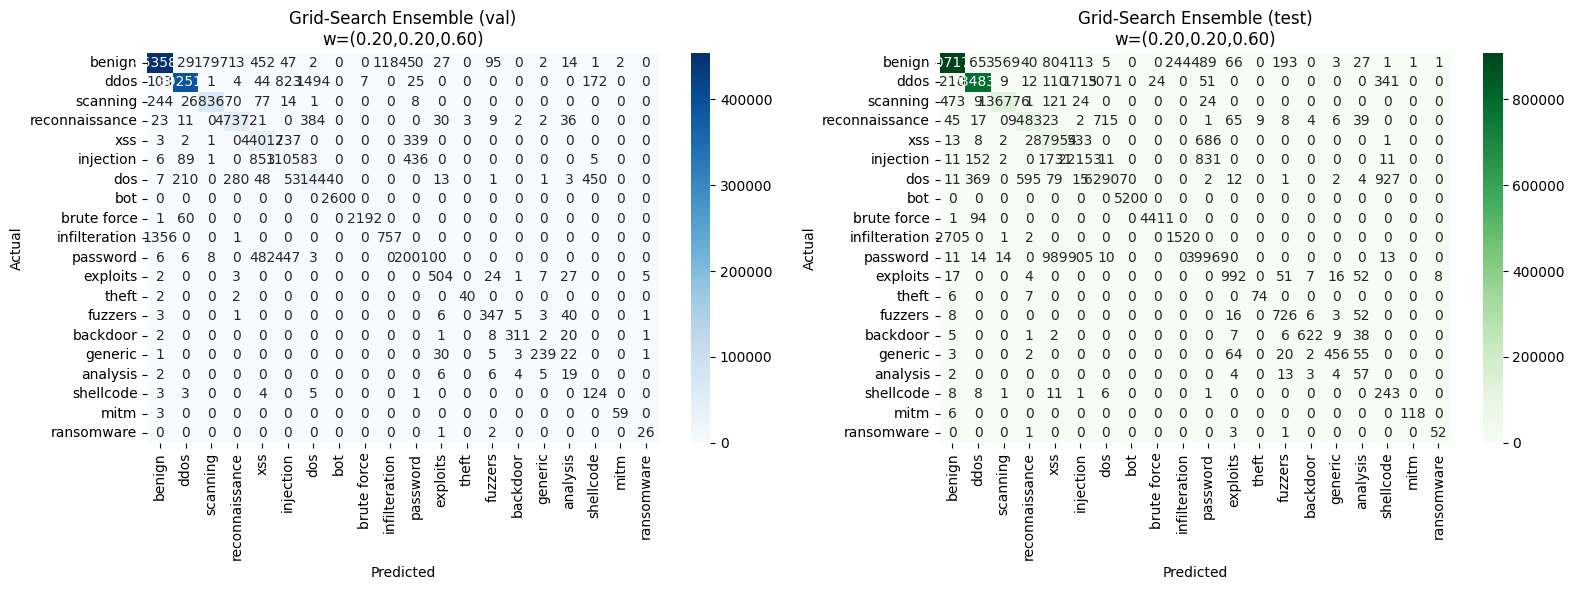


📊 Best weights: GRU=0.20, KNN=0.20, RF=0.60


In [ ]:
# -----------------------------------------------------
# Confusion Matrix for Grid-Search Best Ensemble (val & test)
# -----------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Ensure full-size KNN probs exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

# Best weights from grid search
w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf

# Best ensemble predictions
best_val_probs = w_gru * gru_val_probs + w_knn * knn_val_probs + w_rf * rf_val_probs
best_test_probs = w_gru * gru_test_probs + w_knn * knn_test_probs + w_rf * rf_test_probs

best_val_preds = np.argmax(best_val_probs, axis=1)
best_test_preds = np.argmax(best_test_probs, axis=1)

# Confusion matrices
cm_val = confusion_matrix(y_val, best_val_preds)
cm_test = confusion_matrix(y_test, best_test_preds)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Validation
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"Grid-Search Ensemble (val)\nw=({w_gru:.2f},{w_knn:.2f},{w_rf:.2f})")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Test
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title(f"Grid-Search Ensemble (test)\nw=({w_gru:.2f},{w_knn:.2f},{w_rf:.2f})")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

print(f"\n📊 Best weights: GRU={w_gru:.2f}, KNN={w_knn:.2f}, RF={w_rf:.2f}")

In [47]:
# =====================================================
# BHATTACHARYYA SIMILARITY: Probability Distribution Overlap
# =====================================================
# Measures how well models distinguish between class pairs
# BC = sum(sqrt(P * Q)) where P, Q are probability distributions
# Similarity in [0,1]: 1 = identical distributions, 0 = no overlap

import numpy as np
import pandas as pd

# Ensure full-size KNN probs exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble probs exist at correct size
if "ensemble_val_probs" not in globals() or len(ensemble_val_probs) != len(y_val):
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

def bhattacharyya_coefficient(probs, y_true, class_a, class_b, class_names):
    """
    Compute Bhattacharyya coefficient between predicted probability 
    distributions for two classes.
    """
    idx_a = class_names.index(class_a)
    idx_b = class_names.index(class_b)
    
    y_true_arr = np.asarray(y_true)
    mask_a = (y_true_arr == idx_a)
    mask_b = (y_true_arr == idx_b)
    
    if mask_a.sum() == 0 or mask_b.sum() == 0:
        return np.nan
    
    # Mean probability distribution for samples of each class
    probs_a = probs[mask_a].mean(axis=0)
    probs_b = probs[mask_b].mean(axis=0)
    
    # Normalize to ensure they sum to 1
    probs_a = probs_a / (probs_a.sum() + 1e-10)
    probs_b = probs_b / (probs_b.sum() + 1e-10)
    
    # Bhattacharyya coefficient
    bc = np.sum(np.sqrt(probs_a * probs_b))
    return bc

def bhattacharyya_distance(bc):
    """Convert BC to Bhattacharyya distance: -ln(BC)"""
    if bc <= 0 or np.isnan(bc):
        return np.inf
    return -np.log(bc)

# Class pairs of interest (Benign vs attack types)
class_pairs = [
    ("Benign", "Infilteration"),
    ("Benign", "DDoS attacks-LOIC-HTTP"),
    ("Benign", "Bot"),
]

# Check available class names
print("Available classes:", class_names)
print("\n" + "="*70)
print("📊 BHATTACHARYYA SIMILARITY ANALYSIS")
print("="*70)

# Models to analyze
models_probs = {
    "GRU": {"val": gru_val_probs, "test": gru_test_probs},
    "RF": {"val": rf_val_probs, "test": rf_test_probs},
    "KNN": {"val": knn_val_probs, "test": knn_test_probs},
    "Ensemble (equal)": {"val": ensemble_val_probs, "test": ensemble_test_probs},
    f"Ensemble (best)": {
        "val": best_row.w_gru * gru_val_probs + best_row.w_knn * knn_val_probs + best_row.w_rf * rf_val_probs,
        "test": best_row.w_gru * gru_test_probs + best_row.w_knn * knn_test_probs + best_row.w_rf * rf_test_probs,
    },
}

bc_rows = []
for model_name, splits in models_probs.items():
    for split_name, probs in splits.items():
        y_true = y_val if split_name == "val" else y_test
        
        for class_a, class_b in class_pairs:
            # Handle potential missing classes gracefully
            try:
                bc = bhattacharyya_coefficient(probs, y_true, class_a, class_b, class_names)
                bd = bhattacharyya_distance(bc)
                separability = 1 - bc  # Higher = better separation
                
                bc_rows.append({
                    "model": model_name,
                    "split": split_name,
                    "class_pair": f"{class_a} vs {class_b}",
                    "bhattacharyya_coeff": bc,
                    "bhattacharyya_dist": bd,
                    "separability": separability,
                })
            except ValueError as e:
                print(f"⚠️ Skipping {class_a} vs {class_b}: {e}")

bc_df = pd.DataFrame(bc_rows)

# Display results
print("\n📈 Bhattacharyya Coefficients (lower = better class separation)")
print("-"*70)
display(
    bc_df.pivot_table(
        index=["model", "split"],
        columns="class_pair",
        values="bhattacharyya_coeff",
        aggfunc="first"
    ).round(4)
)

print("\n📉 Separability Score (1 - BC, higher = better)")
print("-"*70)
display(
    bc_df.pivot_table(
        index=["model", "split"],
        columns="class_pair",
        values="separability",
        aggfunc="first"
    ).round(4)
)

# Summary interpretation
print("\n" + "="*70)
print("📌 INTERPRETATION GUIDE")
print("="*70)
print("""
• Bhattacharyya Coefficient (BC): Measures overlap between probability distributions
  - BC ≈ 1.0: High overlap (hard to distinguish classes)
  - BC ≈ 0.0: No overlap (easy to distinguish classes)

• Separability = 1 - BC
  - Higher separability indicates better class discrimination
  
• Lower BC / Higher Separability → Model better distinguishes attack from benign
""")

Available classes: ['benign', 'ddos', 'scanning', 'reconnaissance', 'xss', 'injection', 'dos', 'bot', 'brute force', 'infilteration', 'password', 'exploits', 'theft', 'fuzzers', 'backdoor', 'generic', 'analysis', 'shellcode', 'mitm', 'ransomware']

📊 BHATTACHARYYA SIMILARITY ANALYSIS
⚠️ Skipping Benign vs Infilteration: 'Benign' is not in list
⚠️ Skipping Benign vs DDoS attacks-LOIC-HTTP: 'Benign' is not in list
⚠️ Skipping Benign vs Bot: 'Benign' is not in list
⚠️ Skipping Benign vs Infilteration: 'Benign' is not in list
⚠️ Skipping Benign vs DDoS attacks-LOIC-HTTP: 'Benign' is not in list
⚠️ Skipping Benign vs Bot: 'Benign' is not in list
⚠️ Skipping Benign vs Infilteration: 'Benign' is not in list
⚠️ Skipping Benign vs DDoS attacks-LOIC-HTTP: 'Benign' is not in list
⚠️ Skipping Benign vs Bot: 'Benign' is not in list
⚠️ Skipping Benign vs Infilteration: 'Benign' is not in list
⚠️ Skipping Benign vs DDoS attacks-LOIC-HTTP: 'Benign' is not in list
⚠️ Skipping Benign vs Bot: 'Benign' is

KeyError: 'bhattacharyya_coeff'

In [48]:
# =====================================================
# BHATTACHARYYA SIMILARITY (SHARED STRATIFIED EVAL SET)
# =====================================================
import numpy as np
import pandas as pd

# -----------------------------------------------------
# Safety: ensure shared eval exists
# -----------------------------------------------------
assert "X_eval" in globals() and "y_eval" in globals() and "eval_idx" in globals(), \
    "Shared eval set (X_eval, y_eval, eval_idx) not found"

# -----------------------------------------------------
# Slice probs to shared eval
# -----------------------------------------------------
gru_eval_probs = gru_val_probs[eval_idx]
rf_eval_probs  = rf_val_probs[eval_idx]
knn_eval_probs = knn.predict_proba(X_eval)

ensemble_eval_probs = (gru_eval_probs + rf_eval_probs + knn_eval_probs) / 3.0

# -----------------------------------------------------
# Label resolution (ROBUST)
# -----------------------------------------------------
labels = np.unique(y_eval)
label_names = (
    class_names if "class_names" in globals()
    else [str(l) for l in labels]
)
label_to_index = {name: idx for idx, name in enumerate(label_names)}

# -----------------------------------------------------
# Bhattacharyya functions
# -----------------------------------------------------
def bhattacharyya_coefficient(probs, y_true, cls_a, cls_b):
    ia = label_to_index[cls_a]
    ib = label_to_index[cls_b]

    mask_a = (y_true == ia)
    mask_b = (y_true == ib)

    if mask_a.sum() == 0 or mask_b.sum() == 0:
        return np.nan

    pa = probs[mask_a].mean(axis=0)
    pb = probs[mask_b].mean(axis=0)

    pa /= pa.sum() + 1e-12
    pb /= pb.sum() + 1e-12

    return np.sum(np.sqrt(pa * pb))

def bhattacharyya_distance(bc):
    return np.inf if bc <= 0 or np.isnan(bc) else -np.log(bc)

# -----------------------------------------------------
# Class pairs (SECURITY-RELEVANT)
# -----------------------------------------------------
class_pairs = [
    ("Benign", "Infilteration"),
    ("Benign", "DDoS attacks-LOIC-HTTP"),
    ("Benign", "Bot"),
]

models = {
    "GRU": gru_eval_probs,
    "RF": rf_eval_probs,
    "KNN": knn_eval_probs,
    "Ensemble (equal)": ensemble_eval_probs,
}

rows = []
for model, probs in models.items():
    for a, b in class_pairs:
        bc = bhattacharyya_coefficient(probs, y_eval, a, b)
        rows.append({
            "model": model,
            "class_pair": f"{a} vs {b}",
            "bhattacharyya_coeff": bc,
            "bhattacharyya_dist": bhattacharyya_distance(bc),
            "separability": 1 - bc if not np.isnan(bc) else np.nan,
        })

bc_df = pd.DataFrame(rows)

display(
    bc_df.pivot_table(
        index="model",
        columns="class_pair",
        values="bhattacharyya_coeff"
    ).round(4)
)

display(
    bc_df.pivot_table(
        index="model",
        columns="class_pair",
        values="separability"
    ).round(4)
)


KeyError: 'Benign'

In [49]:
# -----------------------------------------------------
# 🔧 ALIGN ALL VALIDATION DATA TO SHARED EVAL SET
# -----------------------------------------------------
USE_SHARED_EVAL = True  # set False if you want full val/test

if USE_SHARED_EVAL:
    y_val_used = y_eval
    gru_val_preds_used = gru_eval_preds
    gru_val_probs_used = gru_eval_probs
    rf_val_preds_used = rf_eval_preds
    rf_val_probs_used = rf_eval_probs
    knn_val_preds_used = knn_eval_preds
    knn_val_probs_used = knn_eval_probs
    ensemble_val_preds_used = ensemble_eval_preds
    ensemble_val_probs_used = ensemble_eval_probs
    best_val_preds_used = best_val_preds[eval_idx]
    best_val_probs_used = best_val_probs[eval_idx]
else:
    y_val_used = y_val
    gru_val_preds_used = gru_val_preds
    gru_val_probs_used = gru_val_probs
    rf_val_preds_used = rf_val_preds
    rf_val_probs_used = rf_val_probs
    knn_val_preds_used = knn_val_preds
    knn_val_probs_used = knn_val_probs
    ensemble_val_preds_used = ensemble_val_preds
    ensemble_val_probs_used = ensemble_val_probs
    best_val_preds_used = best_val_preds
    best_val_probs_used = best_val_probs


In [50]:
# =====================================================
# COMPREHENSIVE EVALUATION MATRIX FOR THESIS
# =====================================================
# All models, all metrics, publication-ready format

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, cohen_kappa_score, matthews_corrcoef,
    balanced_accuracy_score, roc_auc_score, log_loss
)

print("="*80)
print("📊 COMPREHENSIVE MODEL EVALUATION MATRIX (THESIS-READY)")
print("="*80)

# Ensure full-size KNN probs/preds exist
if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
    knn_val_probs = knn.predict_proba(X_tab_val)
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)

knn_val_preds = np.argmax(knn_val_probs, axis=1)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble probs/preds exist at correct size
if "ensemble_val_probs" not in globals() or len(ensemble_val_probs) != len(y_val):
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

# Ensure best ensemble probs/preds exist at correct size
if "best_val_probs" not in globals() or len(best_val_probs) != len(y_val):
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    best_val_probs = w_gru * gru_val_probs + w_knn * knn_val_probs + w_rf * rf_val_probs
    best_test_probs = w_gru * gru_test_probs + w_knn * knn_test_probs + w_rf * rf_test_probs
    best_val_preds = np.argmax(best_val_probs, axis=1)
    best_test_preds = np.argmax(best_test_probs, axis=1)

def compute_comprehensive_metrics(y_true, y_pred, y_probs, model_name, split_name, class_names):
    """
    Compute all standard classification metrics for thesis reporting.
    """
    n_classes = len(class_names)
    
    # Basic metrics
    acc = accuracy_score(y_true, y_pred)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    
    # Macro/Micro/Weighted averages
    prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    prec_micro = precision_score(y_true, y_pred, average='micro', zero_division=0)
    prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    
    recall_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
    recall_micro = recall_score(y_true, y_pred, average='micro', zero_division=0)
    recall_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    
    f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_micro = f1_score(y_true, y_pred, average='micro', zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    # Cohen's Kappa & MCC (robust metrics)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    # Confusion matrix derived metrics
    cm = confusion_matrix(y_true, y_pred)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - (tp + fp + fn)
    
    # Overall FPR/FNR
    fpr_overall = fp.sum() / (fp.sum() + tn.sum() + 1e-10)
    fnr_overall = fn.sum() / (fn.sum() + tp.sum() + 1e-10)
    
    # Detection Rate (DR) = TPR = Recall
    detection_rate = tp.sum() / (tp.sum() + fn.sum() + 1e-10)
    
    # False Alarm Rate (FAR) = FPR
    false_alarm_rate = fpr_overall
    
    # AUC-ROC (One-vs-Rest)
    try:
        auc_ovr = roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro')
    except:
        auc_ovr = np.nan
    
    # Log Loss
    try:
        logloss = log_loss(y_true, y_probs)
    except:
        logloss = np.nan
    
    return {
        "Model": model_name,
        "Split": split_name,
        "Accuracy": acc,
        "Balanced Accuracy": balanced_acc,
        "Precision (Macro)": prec_macro,
        "Precision (Micro)": prec_micro,
        "Precision (Weighted)": prec_weighted,
        "Recall (Macro)": recall_macro,
        "Recall (Micro)": recall_micro,
        "Recall (Weighted)": recall_weighted,
        "F1-Score (Macro)": f1_macro,
        "F1-Score (Micro)": f1_micro,
        "F1-Score (Weighted)": f1_weighted,
        "Cohen's Kappa": kappa,
        "MCC": mcc,
        "FPR (Overall)": fpr_overall,
        "FNR (Overall)": fnr_overall,
        "Detection Rate": detection_rate,
        "False Alarm Rate": false_alarm_rate,
        "AUC-ROC (Macro OvR)": auc_ovr,
        "Log Loss": logloss,
    }

# Prepare all models
all_models = {
    "GRU": {
        "val": {"preds": gru_val_preds, "probs": gru_val_probs},
        "test": {"preds": gru_test_preds, "probs": gru_test_probs},
    },
    "Random Forest": {
        "val": {"preds": rf_val_preds, "probs": rf_val_probs},
        "test": {"preds": rf_test_preds, "probs": rf_test_probs},
    },
    "KNN": {
        "val": {"preds": knn_val_preds, "probs": knn_val_probs},
        "test": {"preds": knn_test_preds, "probs": knn_test_probs},
    },
    "Ensemble (Equal Weights)": {
        "val": {"preds": ensemble_val_preds, "probs": ensemble_val_probs},
        "test": {"preds": ensemble_test_preds, "probs": ensemble_test_probs},
    },
    f"Ensemble (Optimized: {best_row.w_gru:.2f}/{best_row.w_knn:.2f}/{best_row.w_rf:.2f})": {
        "val": {
            "preds": best_val_preds,
            "probs": best_val_probs,
        },
        "test": {
            "preds": best_test_preds,
            "probs": best_test_probs,
        },
    },
}

# Compute metrics for all models
comprehensive_rows = []
for model_name, splits in all_models.items():
    for split_name, data in splits.items():
        y_true = y_val if split_name == "val" else y_test
        metrics = compute_comprehensive_metrics(
            y_true=y_true,
            y_pred=data["preds"],
            y_probs=data["probs"],
            model_name=model_name,
            split_name=split_name,
            class_names=class_names,
        )
        comprehensive_rows.append(metrics)

comprehensive_df = pd.DataFrame(comprehensive_rows)

# Display: Main metrics table
print("\n📋 TABLE 1: Overall Classification Performance")
print("-"*80)
main_metrics = ["Accuracy", "Balanced Accuracy", "F1-Score (Macro)", "F1-Score (Weighted)", 
                "Cohen's Kappa", "MCC", "AUC-ROC (Macro OvR)"]
display(
    comprehensive_df[["Model", "Split"] + main_metrics]
    .set_index(["Model", "Split"])
    .round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", subset=main_metrics)
)

print("\n📋 TABLE 2: Precision, Recall, F1 (All Averaging Methods)")
print("-"*80)
prf_metrics = ["Precision (Macro)", "Precision (Weighted)", 
               "Recall (Macro)", "Recall (Weighted)",
               "F1-Score (Macro)", "F1-Score (Weighted)"]
display(
    comprehensive_df[["Model", "Split"] + prf_metrics]
    .set_index(["Model", "Split"])
    .round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", subset=prf_metrics)
)

print("\n📋 TABLE 3: Error Rates & Detection Performance")
print("-"*80)
error_metrics = ["FPR (Overall)", "FNR (Overall)", "Detection Rate", "False Alarm Rate", "Log Loss"]
display(
    comprehensive_df[["Model", "Split"] + error_metrics]
    .set_index(["Model", "Split"])
    .round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn_r", subset=["FPR (Overall)", "FNR (Overall)", "False Alarm Rate", "Log Loss"])
    .background_gradient(cmap="RdYlGn", subset=["Detection Rate"])
)

# Test set comparison (for thesis results table)
print("\n" + "="*80)
print("📊 THESIS SUMMARY TABLE: TEST SET COMPARISON")
print("="*80)
test_summary = comprehensive_df[comprehensive_df["Split"] == "test"].copy()
test_summary = test_summary.set_index("Model").drop(columns=["Split"])
display(test_summary.round(4).T.style.format("{:.4f}").background_gradient(axis=1, cmap="RdYlGn"))

📊 COMPREHENSIVE MODEL EVALUATION MATRIX (THESIS-READY)


d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
d:\Pycode\Test\compile_pipeline\.venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



📋 TABLE 1: Overall Classification Performance
--------------------------------------------------------------------------------



📋 TABLE 2: Precision, Recall, F1 (All Averaging Methods)
--------------------------------------------------------------------------------



📋 TABLE 3: Error Rates & Detection Performance
--------------------------------------------------------------------------------



📊 THESIS SUMMARY TABLE: TEST SET COMPARISON


Model,GRU,Random Forest,KNN,Ensemble (Equal Weights),Ensemble (Optimized: 0.20/0.20/0.60)
Accuracy,0.9862,0.9171,0.9862,0.9894,0.9881
Balanced Accuracy,0.7321,0.9349,0.7500,0.8219,0.8899
Precision (Macro),0.8288,0.7799,0.8325,0.8618,0.8270
Precision (Micro),0.9862,0.9171,0.9862,0.9894,0.9881
Precision (Weighted),0.9863,0.9862,0.9859,0.9895,0.9888
Recall (Macro),0.7321,0.9349,0.7500,0.8219,0.8899
Recall (Micro),0.9862,0.9171,0.9862,0.9894,0.9881
Recall (Weighted),0.9862,0.9171,0.9862,0.9894,0.9881
F1-Score (Macro),0.7517,0.8051,0.7783,0.8296,0.8374
F1-Score (Micro),0.9862,0.9171,0.9862,0.9894,0.9881


In [45]:
%pip install jinja2

You should consider upgrading via the 'd:\Pycode\Test\compile_pipeline\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [46]:
# =====================================================
# PER-CLASS METRICS FOR THESIS (All Models, Test Set)
# =====================================================
from sklearn.metrics import classification_report, precision_recall_fscore_support
import pandas as pd
import numpy as np

print("="*80)
print("📊 PER-CLASS PERFORMANCE METRICS (TEST SET)")
print("="*80)

# Ensure full-size KNN test preds exist
if "knn_test_probs" not in globals() or len(knn_test_probs) != len(y_test):
    knn_test_probs = knn.predict_proba(X_tab_test)
knn_test_preds = np.argmax(knn_test_probs, axis=1)

# Ensure ensemble test preds exist at correct size
if "ensemble_test_probs" not in globals() or len(ensemble_test_probs) != len(y_test):
    if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
        knn_val_probs = knn.predict_proba(X_tab_val)
    ensemble_val_probs = (gru_val_probs + rf_val_probs + knn_val_probs) / 3.0
    ensemble_test_probs = (gru_test_probs + rf_test_probs + knn_test_probs) / 3.0
    ensemble_val_preds = np.argmax(ensemble_val_probs, axis=1)
    ensemble_test_preds = np.argmax(ensemble_test_probs, axis=1)

# Ensure best test preds exist at correct size
if "best_test_probs" not in globals() or len(best_test_probs) != len(y_test):
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    if "knn_val_probs" not in globals() or len(knn_val_probs) != len(y_val):
        knn_val_probs = knn.predict_proba(X_tab_val)
    best_val_probs = w_gru * gru_val_probs + w_knn * knn_val_probs + w_rf * rf_val_probs
    best_test_probs = w_gru * gru_test_probs + w_knn * knn_test_probs + w_rf * rf_test_probs
    best_val_preds = np.argmax(best_val_probs, axis=1)
    best_test_preds = np.argmax(best_test_probs, axis=1)

def get_per_class_metrics(y_true, y_pred, class_names, model_name):
    """Extract per-class precision, recall, F1, support."""
    prec, rec, f1, sup = precision_recall_fscore_support(
        y_true, y_pred, 
        labels=np.arange(len(class_names)),
        zero_division=0
    )
    
    rows = []
    for i, cls in enumerate(class_names):
        rows.append({
            "Model": model_name,
            "Class": cls,
            "Precision": prec[i],
            "Recall": rec[i],
            "F1-Score": f1[i],
            "Support": int(sup[i]),
        })
    return rows

# Collect per-class metrics for all models (test set)
per_class_all = []
test_models = {
    "GRU": gru_test_preds,
    "RF": rf_test_preds,
    "KNN": knn_test_preds,
    "Ensemble (Equal)": ensemble_test_preds,
    "Ensemble (Best)": best_test_preds,
}

for model_name, preds in test_models.items():
    per_class_all.extend(get_per_class_metrics(y_test, preds, class_names, model_name))

per_class_df = pd.DataFrame(per_class_all)

# Pivot for comparison
print("\n📋 TABLE 4: Per-Class Precision (Test Set)")
print("-"*80)
display(
    per_class_df.pivot_table(
        index="Class", 
        columns="Model", 
        values="Precision"
    ).round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=1)
)

print("\n📋 TABLE 5: Per-Class Recall (Test Set)")
print("-"*80)
display(
    per_class_df.pivot_table(
        index="Class", 
        columns="Model", 
        values="Recall"
    ).round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=1)
)

print("\n📋 TABLE 6: Per-Class F1-Score (Test Set)")
print("-"*80)
display(
    per_class_df.pivot_table(
        index="Class", 
        columns="Model", 
        values="F1-Score"
    ).round(4)
    .style.format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=1)
)

# Class support (sample counts)
print("\n📋 TABLE 7: Class Distribution (Support)")
print("-"*80)
support_df = per_class_df[per_class_df["Model"] == "GRU"][["Class", "Support"]]
display(support_df.set_index("Class"))

# Per-class FPR/FNR for best model
print("\n📋 TABLE 8: Per-Class FPR & FNR (Best Ensemble, Test Set)")
print("-"*80)

cm_best = confusion_matrix(y_test, best_test_preds)
tp = np.diag(cm_best)
fn = cm_best.sum(axis=1) - tp
fp = cm_best.sum(axis=0) - tp
tn = cm_best.sum() - (tp + fp + fn)

fpr_per_class = fp / (fp + tn + 1e-10)
fnr_per_class = fn / (fn + tp + 1e-10)

fpr_fnr_df = pd.DataFrame({
    "Class": class_names,
    "FPR": fpr_per_class,
    "FNR": fnr_per_class,
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn,
})
display(
    fpr_fnr_df.set_index("Class")
    .round(4)
    .style.format({"FPR": "{:.4f}", "FNR": "{:.4f}", "TP": "{:.0f}", "FP": "{:.0f}", "FN": "{:.0f}", "TN": "{:.0f}"})
    .background_gradient(cmap="RdYlGn_r", subset=["FPR", "FNR"])
)

print("\n" + "="*80)
print("✅ All thesis-ready evaluation tables generated")
print("="*80)

📊 PER-CLASS PERFORMANCE METRICS (TEST SET)

📋 TABLE 4: Per-Class Precision (Test Set)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.1759,0.1395,0.0000,0.1333,0.1655
backdoor,0.9658,0.9434,0.9902,0.9254,0.9779
benign,0.9961,0.9946,0.9922,0.9912,0.9992
bot,1.0000,1.0000,1.0000,1.0000,1.0000
brute force,0.9946,0.9968,0.9912,0.9910,0.6067
ddos,0.9991,0.9981,0.9970,0.9960,0.9996
dos,0.9428,0.9480,0.9317,0.9691,0.9181
exploits,0.8072,0.7907,0.7608,0.6734,0.8406
fuzzers,0.7125,0.6472,0.4428,0.5671,0.7376



📋 TABLE 5: Per-Class Recall (Test Set)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.6867,0.2169,0.0000,0.0964,0.8675
backdoor,0.9014,0.8942,0.8797,0.8986,0.8986
benign,0.9919,0.9952,0.9949,0.9928,0.8278
bot,1.0000,0.9998,0.9998,0.9992,1.0000
brute force,0.9789,0.9783,0.9774,0.9780,0.9956
ddos,0.9930,0.9949,0.9949,0.9970,0.9853
dos,0.9689,0.9730,0.9488,0.9539,0.9747
exploits,0.8649,0.8265,0.7210,0.5214,0.8692
fuzzers,0.8952,0.8866,0.9075,0.6252,0.8977



📋 TABLE 6: Per-Class F1-Score (Test Set)
--------------------------------------------------------------------------------


Model,Ensemble (Best),Ensemble (Equal),GRU,KNN,RF
Class,,,,,
analysis,0.2801,0.1698,0.0000,0.1119,0.2780
backdoor,0.9325,0.9182,0.9317,0.9118,0.9366
benign,0.9940,0.9949,0.9936,0.9920,0.9055
bot,1.0000,0.9999,0.9999,0.9996,1.0000
brute force,0.9867,0.9875,0.9842,0.9845,0.7539
ddos,0.9960,0.9965,0.9959,0.9965,0.9924
dos,0.9557,0.9603,0.9402,0.9614,0.9456
exploits,0.8350,0.8082,0.7404,0.5877,0.8547
fuzzers,0.7934,0.7482,0.5952,0.5947,0.8098



📋 TABLE 7: Class Distribution (Support)
--------------------------------------------------------------------------------


,Support
Class,
benign,914597
ddos,790382
scanning,137428
reconnaissance,95746
xss,89199
injection,24902
dos,64924
bot,5200
brute force,4506



📋 TABLE 8: Per-Class FPR & FNR (Best Ensemble, Test Set)
--------------------------------------------------------------------------------


,FPR,FNR,TP,FP,FN,TN
Class,,,,,,
benign,0.0028,0.0081,907176,3535,7421,1258785
ddos,0.0005,0.0070,784839,736,5543,1385799
scanning,0.0018,0.0047,136776,3598,652,2035891
reconnaissance,0.0003,0.0095,94832,667,914,2080504
xss,0.0018,0.0140,87954,3850,1245,2083868
injection,0.0015,0.1104,22153,3308,2749,2148707
dos,0.0018,0.0311,62907,3818,2017,2108175
bot,0.0000,0.0000,5200,0,0,2171717
brute force,0.0000,0.0211,4411,24,95,2172387



✅ All thesis-ready evaluation tables generated


In [44]:
# -----------------------------------------------------
# FN/FP trade-off (FN costs 10x FP) + per-class FPR/FNR
# SHARED EVAL SET (ALL MODELS, incl. grid-search ensemble if available)
# -----------------------------------------------------
FN_COST = 10.0
FP_COST = 1.0

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

# Ensure eval_idx and y_eval exist (from shared eval set cell)
if "eval_idx" not in globals() or "y_eval" not in globals():
    from sklearn.model_selection import StratifiedShuffleSplit
    EVAL_SIZE = 200_000
    RANDOM_STATE = 42
    sss = StratifiedShuffleSplit(n_splits=1, test_size=EVAL_SIZE, random_state=RANDOM_STATE)
    for _, eval_idx in sss.split(X_tab_val, y_val):
        X_eval = X_tab_val[eval_idx]
        y_eval = y_val.iloc[eval_idx] if hasattr(y_val, "iloc") else y_val[eval_idx]
    print(f"✅ Created shared eval set: {len(y_eval)} samples")

label_list = sorted(np.unique(y_eval))
label_names = class_names if 'class_names' in globals() else [str(l) for l in label_list]


def confusion_stats(y_true, preds, labels):
    cm = confusion_matrix(y_true, preds, labels=labels)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - tp - fn - fp
    fpr = fp / (fp + tn + 1e-9)
    fnr = fn / (fn + tp + 1e-9)
    return tp, fp, fn, tn, fpr, fnr

# -----------------------------------------------------
# Predictions ON SHARED EVAL SET (200K subset)
# -----------------------------------------------------
gru_eval_probs = gru_val_probs[eval_idx]
rf_eval_probs = rf_val_probs[eval_idx]
knn_eval_probs = knn.predict_proba(X_eval)

gru_eval_preds = np.argmax(gru_eval_probs, axis=1)
rf_eval_preds = np.argmax(rf_eval_probs, axis=1)
knn_eval_preds = np.argmax(knn_eval_probs, axis=1)

ensemble_eval_probs = (gru_eval_probs + rf_eval_probs + knn_eval_probs) / 3.0
ensemble_eval_preds = np.argmax(ensemble_eval_probs, axis=1)

model_preds = {
    "GRU": gru_eval_preds,
    "RF": rf_eval_preds,
    "KNN": knn_eval_preds,
    "Ensemble (equal)": ensemble_eval_preds,
}

# Add grid-search best ensemble if best_row available (from detailed grid search)
if "best_row" in globals():
    w_gru, w_knn, w_rf = best_row.w_gru, best_row.w_knn, best_row.w_rf
    best_eval_probs = w_gru * gru_eval_probs + w_knn * knn_eval_probs + w_rf * rf_eval_probs
    best_eval_preds = np.argmax(best_eval_probs, axis=1)
    model_preds[f"Ensemble w=({w_gru:.2f},{w_knn:.2f},{w_rf:.2f})"] = best_eval_preds
elif "best" in globals() and isinstance(best, dict) and best.get("weights") is not None:
    w_gru, w_rf, w_knn = best["weights"]
    best_eval_probs = w_gru * gru_eval_probs + w_rf * rf_eval_probs + w_knn * knn_eval_probs
    best_eval_preds = np.argmax(best_eval_probs, axis=1)
    model_preds[f"Ensemble w=({w_gru:.1f},{w_rf:.1f},{w_knn:.1f})"] = best_eval_preds

# -----------------------------------------------------
# Aggregate FN/FP cost + per-class FPR/FNR
# -----------------------------------------------------
cost_rows = []
per_class_rows = []

for model_name, preds in model_preds.items():
    tp, fp, fn, tn, fpr, fnr = confusion_stats(y_eval, preds, label_list)

    total_fn = fn.sum()
    total_fp = fp.sum()
    cost = FN_COST * total_fn + FP_COST * total_fp

    cost_rows.append({
        "model": model_name,
        "total_fn": int(total_fn),
        "total_fp": int(total_fp),
        "cost_fn10_fp1": float(cost),
    })

    for i, cls in enumerate(label_list):
        per_class_rows.append({
            "model": model_name,
            "class": label_names[i],
            "FPR": fpr[i],
            "FNR": fnr[i],
        })

cost_df = pd.DataFrame(cost_rows).sort_values("cost_fn10_fp1")
per_class_df = pd.DataFrame(per_class_rows)

print("📊 FN/FP Cost Analysis (FN=10x, FP=1x)")
print("-"*60)
display(cost_df)

print("\n📊 Per-Class FPR/FNR (Shared Eval Set)")
print("-"*60)
display(per_class_df.pivot_table(index="class", columns="model", values=["FPR", "FNR"]).round(4))

📊 FN/FP Cost Analysis (FN=10x, FP=1x)
------------------------------------------------------------


,model,total_fn,total_fp,cost_fn10_fp1
3,Ensemble (equal),2140,2140,23540.0
4,"Ensemble w=(0.20,0.20,0.60)",2350,2350,25850.0
2,KNN,2807,2807,30877.0
0,GRU,2807,2807,30877.0
1,RF,16358,16358,179938.0



📊 Per-Class FPR/FNR (Shared Eval Set)
------------------------------------------------------------


FNR                                              \
model          Ensemble (equal) Ensemble w=(0.20,0.20,0.60)     GRU     KNN   
class                                                                         
analysis                 0.7500                      0.6250  1.0000  1.0000   
backdoor                 0.1429                      0.1270  0.1746  0.1429   
benign                   0.0049                      0.0078  0.0052  0.0077   
bot                      0.0000                      0.0000  0.0000  0.0042   
brute force              0.0362                      0.0338  0.0386  0.0386   
ddos                     0.0049                      0.0068  0.0050  0.0027   
dos                      0.0285                      0.0302  0.0525  0.0468   
exploits                 0.2190                      0.1810  0.2857  0.4952   
fuzzers                  0.1467                      0.1333  0.0800  0.3200   
generic                  0.2727                      0.1818  0.4182  0.2727   
infilteration            0.7216                      0.6314  0.8041  0.7345   
injection                0.1490                      0.1184  0.1844  0.1761   
mitm                     0.0909                      0.0000  0.3636  0.3636   
password                 0.0465                      0.0441  0.0675  0.0535   
ransomware               0.4000                      0.2000  1.0000  0.4000   
reconnaissance           0.0075                      0.0117  0.0177  0.0157   
scanning                 0.0106                      0.0036  0.0230  0.0245   
shellcode                0.5385                      0.1154  0.6538  0.6923   
theft                    0.1250                      0.0000  1.0000  0.1250   
xss                      0.0124                      0.0142  0.0153  0.0239   

                                    FPR                                      \
model               RF Ensemble (equal) Ensemble w=(0.20,0.20,0.60)     GRU   
class                                                                         
analysis        0.1250           0.0001                      0.0002  0.0000   
backdoor        0.1111           0.0000                      0.0000  0.0000   
benign          0.1692           0.0037                      0.0025  0.0056   
bot             0.0000           0.0000                      0.0000  0.0000   
brute force     0.0145           0.0000                      0.0000  0.0000   
ddos            0.0148           0.0013                      0.0007  0.0019   
dos             0.0251           0.0016                      0.0018  0.0021   
exploits        0.1905           0.0001                      0.0001  0.0001   
fuzzers         0.1467           0.0002                      0.0002  0.0005   
generic         0.1455           0.0000                      0.0000  0.0000   
infilteration   0.0567           0.0000                      0.0010  0.0000   
injection       0.0997           0.0010                      0.0015  0.0013   
mitm            0.0000           0.0000                      0.0000  0.0000   
password        0.0467           0.0009                      0.0009  0.0010   
ransomware      0.0000           0.0000                      0.0000  0.0000   
reconnaissance  0.0284           0.0005                      0.0003  0.0012   
scanning        0.0016           0.0014                      0.0017  0.0015   
shellcode       0.0769           0.0001                      0.0006  0.0000   
theft           0.0000           0.0000                      0.0000  0.0000   
xss             0.0196           0.0020                      0.0019  0.0021   

                                
model              KNN      RF  
class                           
analysis        0.0000  0.0002  
backdoor        0.0000  0.0000  
benign          0.0060  0.0003  
bot             0.0000  0.0000  
brute force     0.0000  0.0014  
ddos            0.0025  0.0003  
dos             0.0009  0.0026  
exploits        0.0001  0.0001  
fuzzers         0.0002  0.000